<a href="https://colab.research.google.com/github/nahdaauliya/PCVK_Ganjil_2026/blob/main/week7_PCVK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

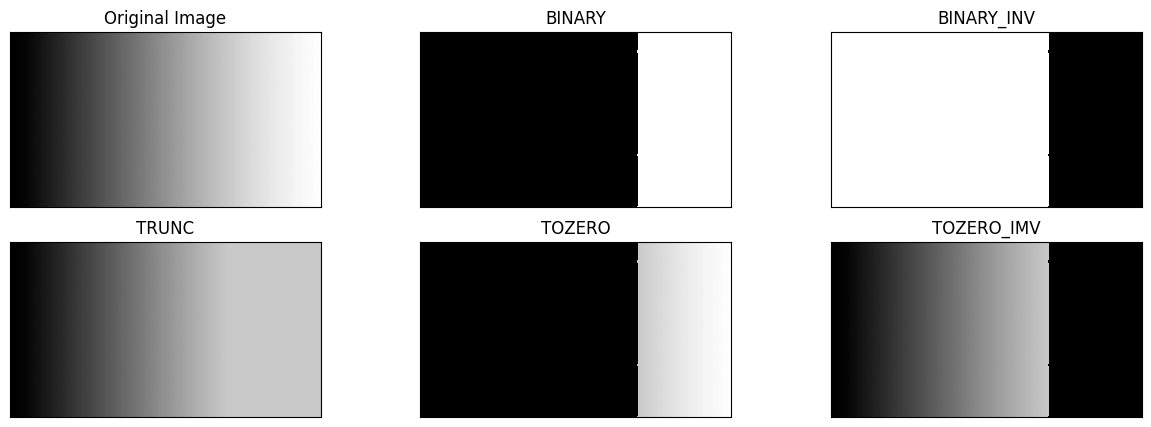

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK/Images/gradient.jpg')
thresh = 200
maxval = 255

ret, thresh1 = cv.threshold(img, thresh, maxval, cv.THRESH_BINARY)

ret, thresh2 = cv.threshold(img, thresh, maxval, cv.THRESH_BINARY_INV)

ret, thresh3 = cv.threshold(img, thresh, maxval, cv.THRESH_TRUNC)

ret, thresh4 = cv.threshold(img, thresh, maxval, cv.THRESH_TOZERO)

ret, thresh5 = cv.threshold(img, thresh, maxval, cv.THRESH_TOZERO_INV)

titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_IMV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize = (15, 5))
for i in range(len(images)):
  plt.subplot(2,3,i+1), plt.imshow(images[i], 'gray', interpolation='nearest')
  plt.title(titles[i])
  plt.xticks([]), plt.yticks([])
plt.show()

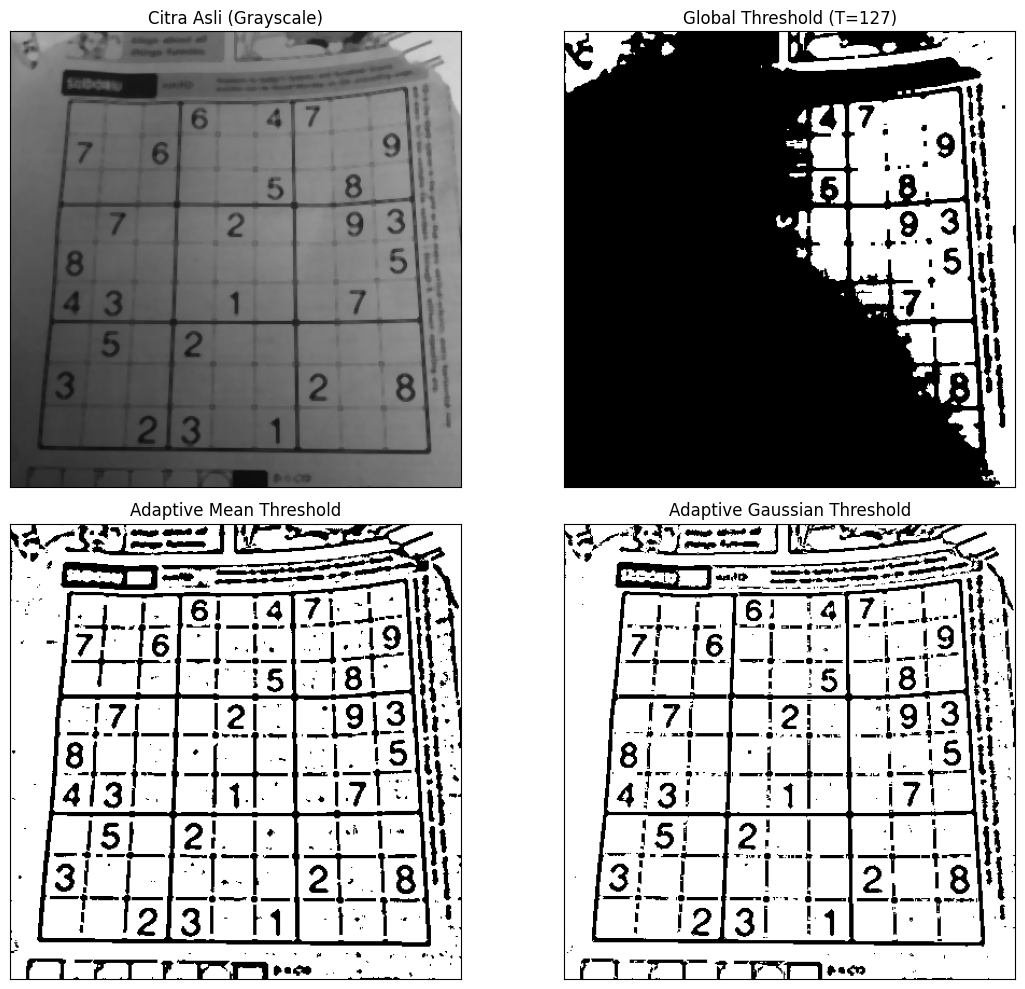

In [ ]:
filename = '/content/drive/MyDrive/PCVK/Images/sudoku-original.jpg'
citra = cv.imread(filename)
gray = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)

def median_blur_manual(image, ksize=5):
    pad = ksize // 2
    padded = np.pad(image, pad, mode='edge')
    output = np.zeros_like(image)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            window = padded[i:i+ksize, j:j+ksize]
            output[i, j] = np.median(window)

    return output

gray = median_blur_manual(gray, 5)

def global_threshold_manual(image, threshold=127):
    result = np.zeros_like(image)
    result[image > threshold] = 255
    return result

th1 = global_threshold_manual(gray, 127)

def adaptive_mean_manual(image, block_size=11, C=2):
    pad = block_size // 2
    padded = np.pad(image.astype(np.float64),
                    pad, mode='reflect')

    output = np.zeros_like(image)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            window = padded[i:i+block_size, j:j+block_size]

            mean_value = np.mean(window)
            threshold = mean_value - C

            if image[i, j] > threshold:
                output[i, j] = 255
            else:
                output[i, j] = 0

    return output

th2 = adaptive_mean_manual(gray, 11, 2)

def gaussian_kernel(size=11, sigma=2):
    ax = np.arange(-(size // 2), size // 2 + 1)
    xx, yy = np.meshgrid(ax, ax)

    kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    kernel = kernel / np.sum(kernel)

    return kernel

def convolution_manual(image, kernel):
    ksize = kernel.shape[0]
    pad = ksize // 2

    padded = np.pad(image.astype(np.float64),
                    pad, mode='reflect')

    output = np.zeros(image.shape, dtype=np.float64)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            window = padded[i:i+ksize, j:j+ksize]
            output[i, j] = np.sum(window * kernel)

    return output

def adaptive_gaussian_manual(image, block_size=11,
                             C=2, sigma=2):
    kernel = gaussian_kernel(block_size, sigma)
    weighted_mean = convolution_manual(image, kernel)

    threshold = weighted_mean - C
    output = np.where(image > threshold, 255, 0)

    return output.astype(np.uint8)

th3 = adaptive_gaussian_manual(gray, 11, 2, 2)

titles = [
    'Citra Asli (Grayscale)',
    'Global Threshold (T=127)',
    'Adaptive Mean Threshold',
    'Adaptive Gaussian Threshold'
]

images = [gray, th1, th2, th3]

plt.figure(figsize=(12, 10))

for i in range(len(images)):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

93


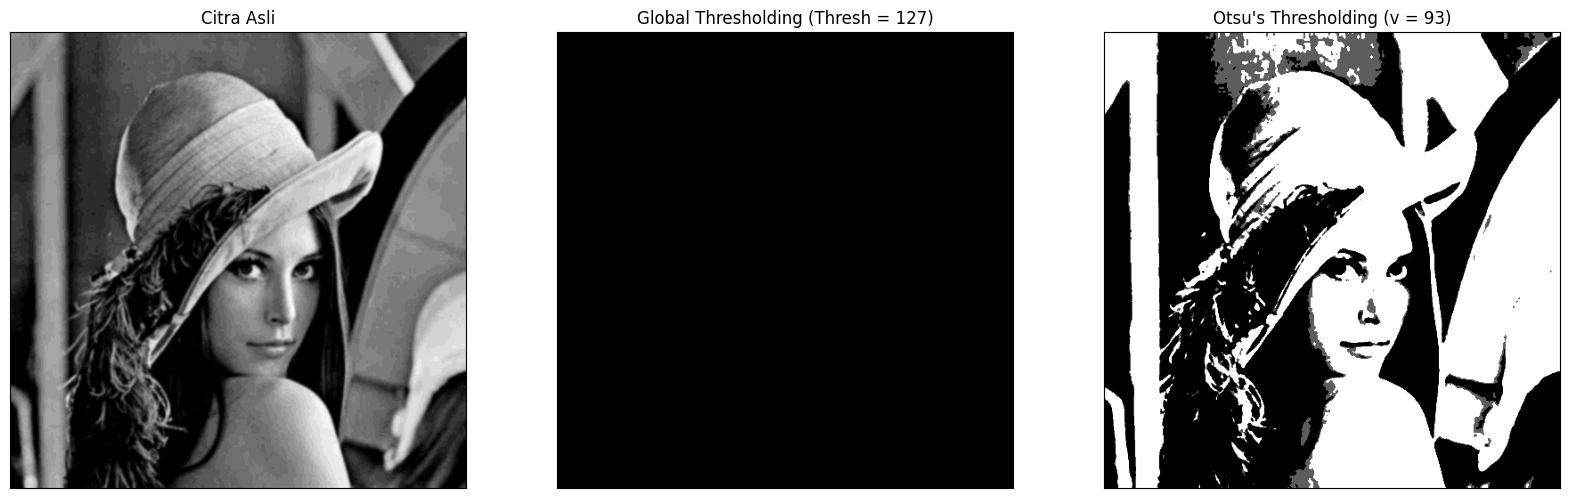

In [ ]:
filename = ('/content/drive/MyDrive/PCVK/Images/lena_gs_lc2.jpg')
img = cv.imread (filename, 0)
blur = cv.GaussianBlur (img, (5,5),0)
thresh=127

def otsu (gray) :
  pixel_number = gray.shape [0] * gray.shape [1]
  mean_weight = 1.0/pixel_number
  his, bins = np.histogram(gray, np.arange (0,257))
  final_thresh = -1
  final_value = -1
  intensity_arr = np.arange (256)
  for t in bins [1:-1]:
    pcb = np.sum(his[:t])
    pcf = np.sum(his[t:])
    if pcb == 0 or pcf == 0:
            continue
    Wb = pcb * mean_weight
    Wf = pcf * mean_weight

    mub = np.sum(intensity_arr[:t]*his[:t])/float(pcb)
    muf = np.sum(intensity_arr[t:]*his[t:])/float(pcf)
    value = Wb * Wf * (mub - muf) ** 2

    if value > final_value:
      final_thresh = t
      final_value = value
  final_img = gray.copy ()
  print(final_thresh)
  final_img[gray > final_thresh] = 255
  final_img[gray < final_thresh] = 0
  return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ") +str (otsu_thresh) +")"
ret, th1 = cv. threshold (blur, thresh, 255, cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str (thresh) +')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure (figsize = (20,15))
for i in range(len(citra3)) :
  plt.subplot(1,3,i+1), plt.imshow(citra3[i], 'gray')
  plt.title (titles [i])
  plt.xticks([]),plt.yticks ([])
plt.show()

Hasil Binary Thresholding dapat terlihat hitam seluruhnya apabila nilai intensitas piksel citra berada di bawah atau sama dengan nilai ambang batas yang ditentukan. Pada metode Binary Thresholding, piksel dengan intensitas lebih besar dari threshold akan diubah menjadi putih (255), sedangkan piksel dengan intensitas lebih kecil atau sama dengan threshold akan diubah menjadi hitam (0).

Berdasarkan histogram, kondisi ini dapat terjadi apabila seluruh atau sebagian besar distribusi intensitas piksel berada di sebelah kiri nilai threshold. Untuk mengetahui nilai ambang yang tepat agar gambar Lena masih terlihat, histogram perlu dianalisis dan beberapa nilai threshold perlu diuji. Nilai threshold yang lebih rendah dapat menampilkan lebih banyak bagian putih, tetapi nilai terbaik bergantung pada distribusi intensitas citra.

Global Threshold: 127
Otsu Threshold: 165


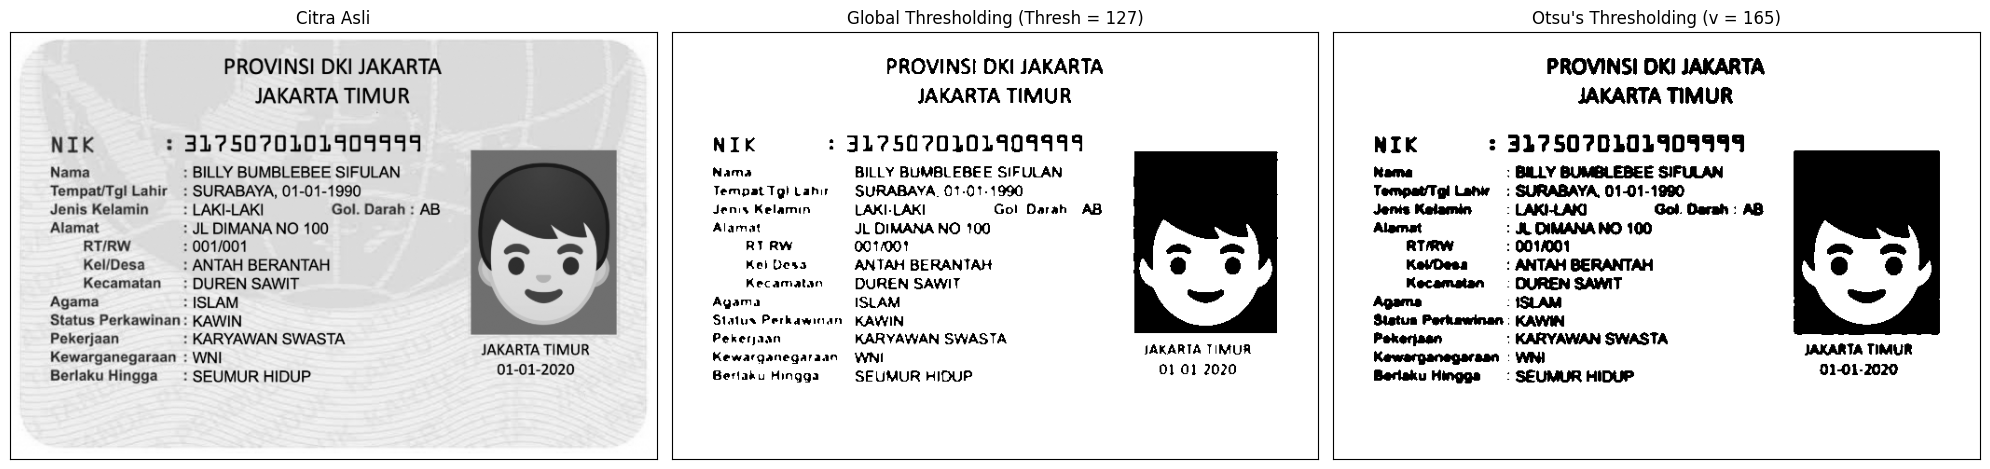

In [ ]:
filename = '/content/drive/MyDrive/PCVK/Images/ktp1.jpg'
img = cv.imread(filename, 0)

if img is None:
    raise FileNotFoundError(
        "Gambar tidak ditemukan. Periksa nama dan lokasi file."
    )

blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127
ret, th1 = cv.threshold(
    blur, thresh, 255, cv.THRESH_BINARY
)

def otsu(gray):
    pixel_number = gray.size
    his, bins = np.histogram(
        gray.ravel(), bins=256, range=(0, 256)
    )

    intensity_arr = np.arange(256)
    final_thresh = 0
    final_value = -1

    for t in range(256):
        pcb = np.sum(his[:t + 1])
        pcf = np.sum(his[t + 1:])

        if pcb == 0 or pcf == 0:
            continue

        Wb = pcb / pixel_number
        Wf = pcf / pixel_number

        mub = np.sum(
            intensity_arr[:t + 1] * his[:t + 1]
        ) / pcb

        muf = np.sum(
            intensity_arr[t + 1:] * his[t + 1:]
        ) / pcf

        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_value = value
            final_thresh = t

    final_img = np.where(
        gray > final_thresh, 255, 0
    ).astype(np.uint8)

    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)

print("Global Threshold:", thresh)
print("Otsu Threshold:", otsu_thresh)

titles = [
    'Citra Asli',
    'Global Thresholding (Thresh = 127)',
    "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"
]

images = [img, th1, otsu_biner]

plt.figure(figsize=(20, 6))

for i in range(len(images)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

Seed (baris, kolom): (36, 43) | intensitas: 159


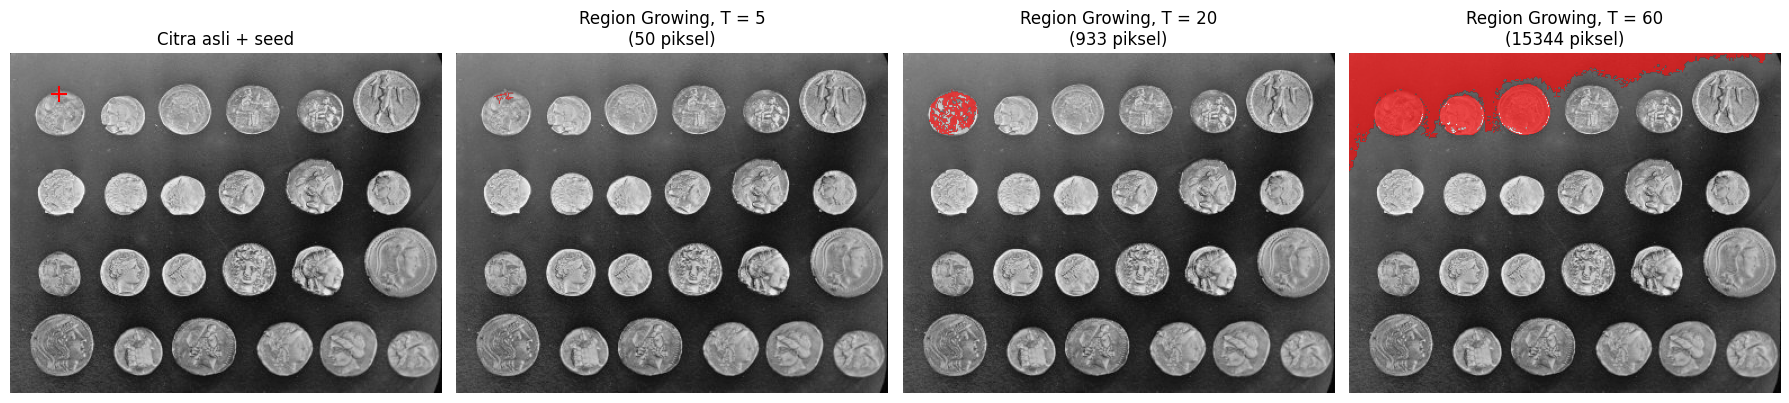

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from collections import deque

img = data.coins()
seed = (36, 43)
T_values = [5, 20, 60]

print(
    f"Seed (baris, kolom): {seed} | "
    f"intensitas: {img[seed]}"
)

def region_growing(image, seed, T):
    rows, cols = image.shape
    seed_value = float(image[seed])

    visited = np.zeros(image.shape, dtype=bool)
    region = np.zeros(image.shape, dtype=bool)

    queue = deque([seed])
    visited[seed] = True

    neighbors = [
        (-1, -1), (-1, 0), (-1, 1),
        (0, -1),           (0, 1),
        (1, -1),  (1, 0),  (1, 1)
    ]

    while queue:
        r, c = queue.popleft()
        region[r, c] = True

        for dr, dc in neighbors:
            nr, nc = r + dr, c + dc

            if 0 <= nr < rows and 0 <= nc < cols:
                if not visited[nr, nc]:
                    visited[nr, nc] = True

                    if abs(float(image[nr, nc]) - seed_value) <= T:
                        queue.append((nr, nc))

    return region

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(img, cmap='gray')
axes[0].scatter(seed[1], seed[0], color='red',
                marker='+', s=120)
axes[0].set_title('Citra asli + seed')
axes[0].axis('off')

for i, T in enumerate(T_values):
    region = region_growing(img, seed, T)
    overlay = np.zeros((*img.shape, 4))
    overlay[region] = [1, 0, 0, 0.65]

    axes[i + 1].imshow(img, cmap='gray')
    axes[i + 1].imshow(overlay)

    axes[i + 1].set_title(
        f'Region Growing, T = {T}\n'
        f'({np.sum(region)} piksel)'
    )
    axes[i + 1].axis('off')

plt.tight_layout()
plt.show()


Seed (baris, kolom): (36, 43) | intensitas: 159.000000
Toleransi 5: 21 piksel
Toleransi 20: 919 piksel
Toleransi 60: 15253 piksel


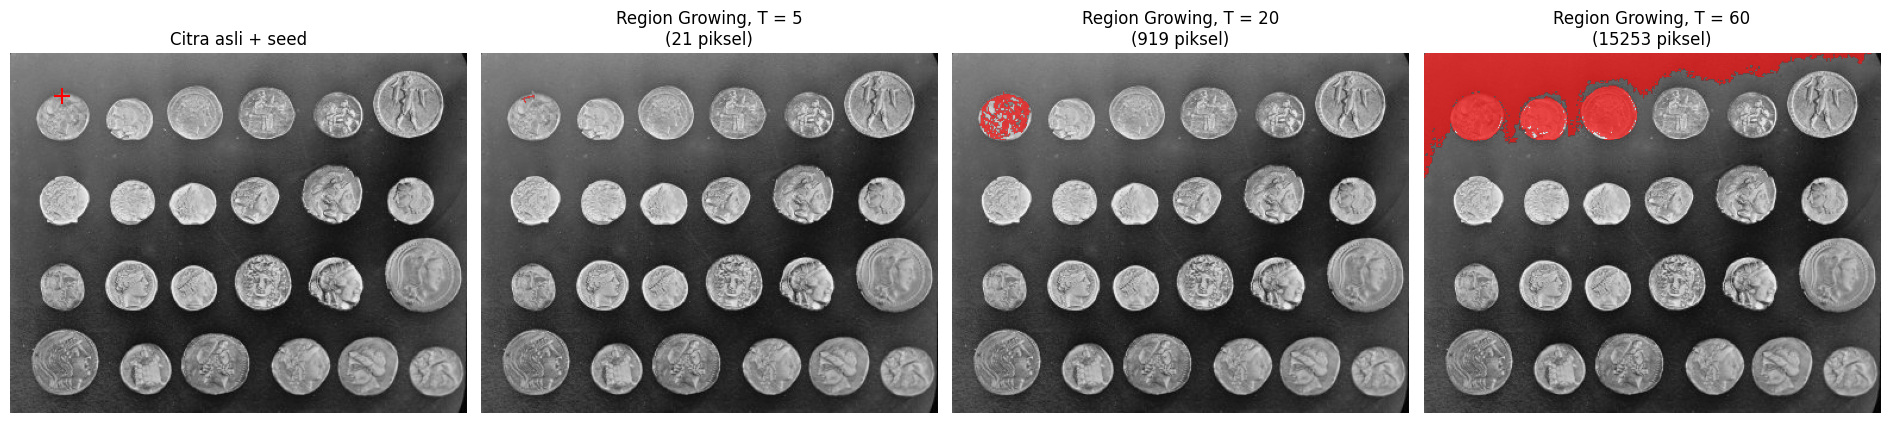

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.segmentation import flood

gray = data.coins()
seed = (36, 43)
tolerances = [5, 20, 60]

print(f"Seed (baris, kolom): {seed} | "
      f"intensitas: {gray[seed]:.6f}")

fig, axes = plt.subplots(1, 4, figsize=(19, 5))
axes[0].imshow(gray, cmap='gray')
axes[0].scatter(
    seed[1], seed[0],
    color='red', marker='+', s=120
)
axes[0].set_title('Citra asli + seed')
axes[0].axis('off')

for i, T in enumerate(tolerances):
    region = flood(
        gray,
        seed_point=seed,
        tolerance=T,
        connectivity=1
    )

    jumlah_piksel = np.sum(region)
    print(f"Toleransi {T}: {jumlah_piksel} piksel")

    overlay = np.zeros((*gray.shape, 4))
    overlay[region] = [1, 0, 0, 0.65]

    axes[i + 1].imshow(gray, cmap='gray')
    axes[i + 1].imshow(overlay)

    axes[i + 1].set_title(
        f'Region Growing, T = {T}\n'
        f'({jumlah_piksel} piksel)'
    )
    axes[i + 1].axis('off')

plt.tight_layout()
plt.show()

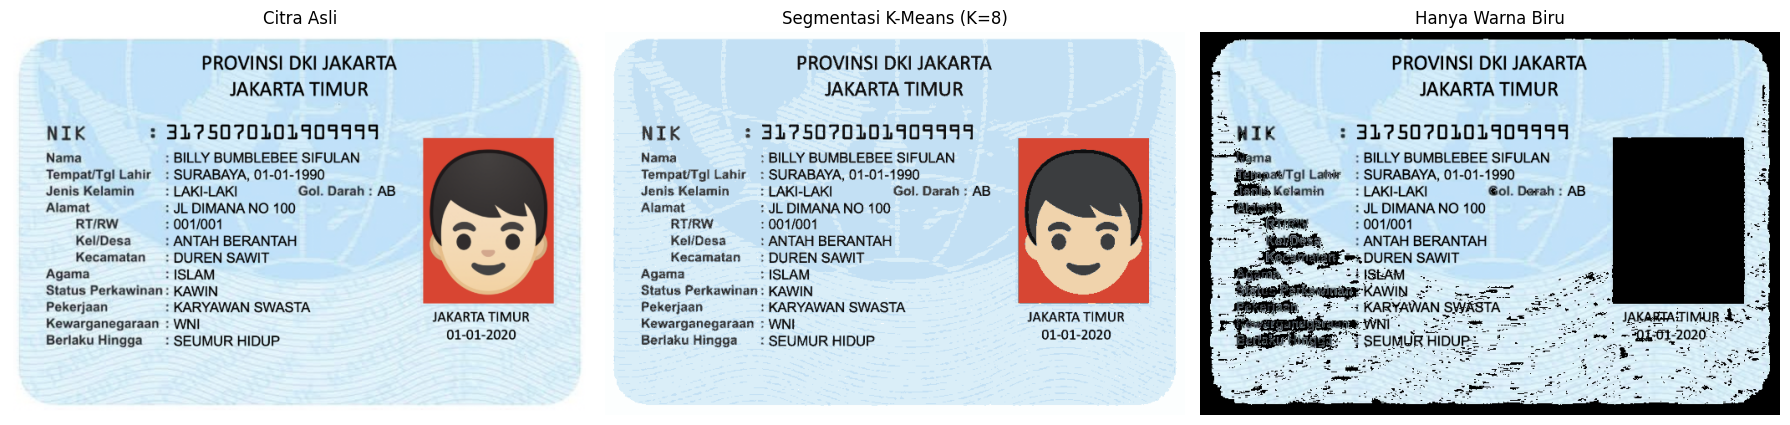

In [8]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

filename = '/content/drive/MyDrive/PCVK/Images/ktp1.jpg'
img = cv.imread(filename)

if img is None:
    raise FileNotFoundError(
        "Gambar tidak ditemukan. Periksa lokasi dan nama file."
    )

img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
pixel_values = img.reshape((-1, 3))
pixel_values = np.float32(pixel_values)

criteria = (
    cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER,
    100,
    0.2
)

K = 8

compactness, labels, centers = cv.kmeans(
    pixel_values,
    K,
    None,
    criteria,
    10,
    cv.KMEANS_PP_CENTERS
)

centers = np.uint8(centers)
segmented = centers[labels.flatten()]
segmented = segmented.reshape(img.shape)
segmented_rgb = cv.cvtColor(
    segmented, cv.COLOR_BGR2RGB
)

hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)
lower_blue = np.array([85, 25, 40])
upper_blue = np.array([130, 255, 255])

mask_blue = cv.inRange(
    hsv, lower_blue, upper_blue
)

blue_only = cv.bitwise_and(
    img, img, mask=mask_blue
)

blue_only_rgb = cv.cvtColor(
    blue_only, cv.COLOR_BGR2RGB
)

titles = [
    'Citra Asli',
    'Segmentasi K-Means (K=8)',
    'Hanya Warna Biru'
]

images = [
    img_rgb,
    segmented_rgb,
    blue_only_rgb
]

plt.figure(figsize=(18, 7))

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i])
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

#D2. Tugas Kelompok

In [10]:
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract opencv-python-headless pandas

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


##1. Baca gambar KTP dan buat tiga versi citra

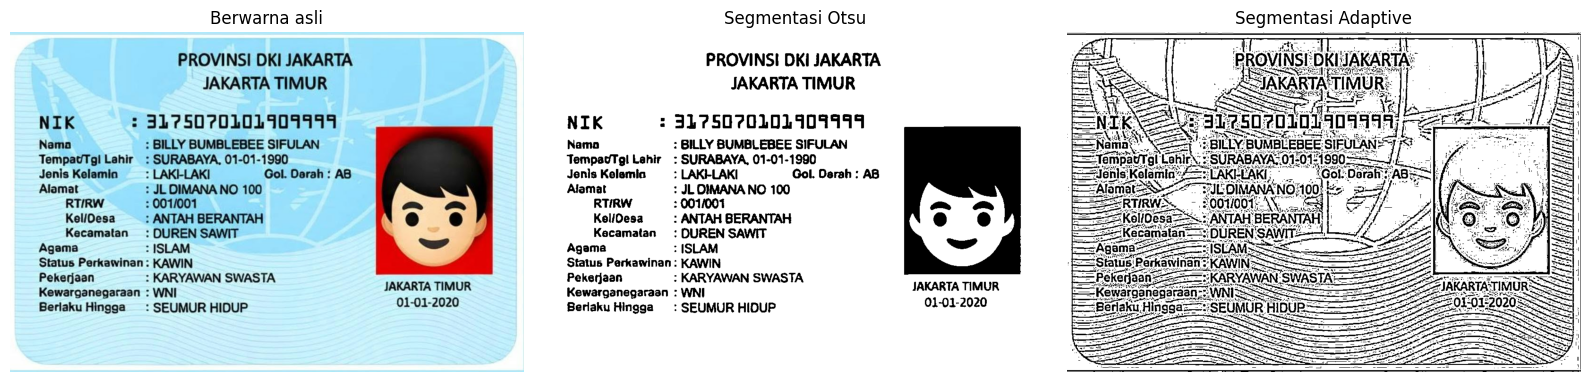

In [19]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
import pandas as pd

from google.colab import drive
from pytesseract import Output

filename = '/content/drive/MyDrive/PCVK/Images (1)/Images/ktp.jpeg'
img = cv2.imread(filename)

if img is None:
    raise FileNotFoundError("File KTP tidak ditemukan. Periksa nama dan lokasi file.")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
_, otsu = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

adaptive = cv2.adaptiveThreshold(
    gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11,
    2
)

images = {
    'Berwarna asli': cv2.cvtColor(img, cv2.COLOR_BGR2RGB),
    'Segmentasi Otsu': otsu,
    'Segmentasi Adaptive': adaptive
}

plt.figure(figsize=(16, 6))
for i, (name, image) in enumerate(images.items()):
    plt.subplot(1, 3, i + 1)
    plt.imshow(image, cmap='gray' if image.ndim == 2 else None)
    plt.title(name)
    plt.axis('off')

plt.tight_layout()
plt.show()

##2. Jalankan OCR pada ketiga citra

In [17]:
config = '--psm 6'
ocr_results = {}
boxed_images = {}
confidence_summary = {}

for name, image in images.items():
    if image.ndim == 3:
        ocr_input = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
    else:
        ocr_input = image

    text_result = pytesseract.image_to_string(
        ocr_input,
        lang='ind',
        config=config
    )
    data = pytesseract.image_to_data(
        ocr_input,
        lang='ind',
        config=config,
        output_type=Output.DICT
    )

    if ocr_input.ndim == 2:
        boxed = cv2.cvtColor(
            ocr_input, cv2.COLOR_GRAY2RGB
        )
    else:
        boxed = cv2.cvtColor(
            ocr_input, cv2.COLOR_BGR2RGB
        )

    valid_conf = []

    for i in range(len(data['text'])):
        word = data['text'][i].strip()

        try:
            conf = float(data['conf'][i])
        except ValueError:
            continue

        if word and conf >= 60:
            x = data['left'][i]
            y = data['top'][i]
            w = data['width'][i]
            h = data['height'][i]

            cv2.rectangle(
                boxed,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

            valid_conf.append(conf)

    ocr_results[name] = text_result
    boxed_images[name] = boxed

    confidence_summary[name] = (
        np.mean(valid_conf) if valid_conf else 0
    )

    print(f'\n{"=" * 50}')
    print(name)
    print("=" * 50)
    print(text_result)


Berwarna asli
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 31?5070101404441
Nama : BILLY BUMBLEBEE SIFULAN
TempatTgi Lahir : SURABAYA. 01-01-1990
Jenis Kelamia 1 LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

Kel/desa : ANTAH BERANTAH h

Kecamatan : DUREN SAWIT
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan 1 KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA Bra
Berlaku Hingga — : SEUMUR HIDUP 01-01-202


Segmentasi Otsu
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 31?5070101909944
Nama 1 BILLY BUMBLEBEE SIFULAN
TempavTgi Lahir : SURABAYA, 01-01-1990
Jenis Kelamin : LAKI-LAKI Gol. Derah : AB
Alamat ? JL DIMANA NO 100

RTIRW : 0011001

Kol/Desa 1 ANTAH BERANTAH

Kecamatan : DUREN SAWIT
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga : SEUMUR HIDUP 01-01-2020


Segmentasi Adaptive
se) i Te Ai —e — sdt 1 7 PK
na #ROVINSI DKIJAKARTA: dh IA
AI | gE JAKARTA TIMUR. | ne NS
NIK SA Aheal (DO L ——— LH
AA asn at, Ko
—-Nama "NE

##3. Tampilkan area teks yang dikenali

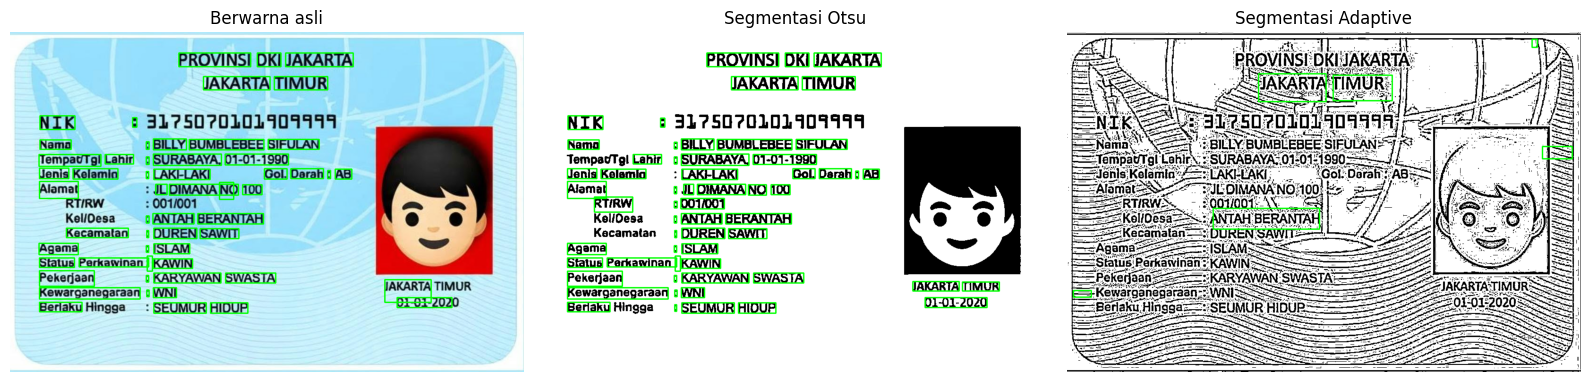

In [18]:
plt.figure(figsize=(16, 7))

for i, (name, boxed) in enumerate(boxed_images.items()):
    plt.subplot(1, 3, i + 1)
    plt.imshow(boxed)
    plt.title(name)
    plt.axis('off')

plt.tight_layout()
plt.show()

##4.  Bandingkan 10 item teks

In [15]:
reference = [
    'PROVINSI',
    'JAKARTA',
    'TIMUR',
    'NIK',
    'Nama',
    'Tempat/Tgl',
    'Lahir',
    'Jenis',
    'Kelamin',
    'Agama'
]

def normalize(text):
    return ' '.join(str(text).strip().lower().split())

ocr_lines = {}

for name, text_result in ocr_results.items():
    ocr_lines[name] = [
        normalize(line)
        for line in text_result.splitlines()
        if line.strip()
    ]

table_rows = []

for item in reference:
    row = {'Teks sebenarnya': item}

    for name, text_result in ocr_results.items():
        normalized_result = normalize(text_result)

        import re
        pattern = r'(?<!\w)' + re.escape(
            normalize(item)
        ) + r'(?!\w)'

        match = bool(re.search(pattern, normalized_result))

        row[name] = 'Cocok' if match else 'Tidak cocok'

    table_rows.append(row)

comparison = pd.DataFrame(table_rows)
display(comparison)


,Teks sebenarnya,Berwarna asli,Segmentasi Otsu,Segmentasi Adaptive
0,PROVINSI,Cocok,Cocok,Tidak cocok
1,JAKARTA,Cocok,Cocok,Cocok
2,TIMUR,Cocok,Cocok,Cocok
3,NIK,Cocok,Cocok,Cocok
4,Nama,Cocok,Cocok,Cocok
5,Tempat/Tgl,Tidak cocok,Tidak cocok,Cocok
6,Lahir,Cocok,Cocok,Cocok
7,Jenis,Cocok,Cocok,Cocok
8,Kelamin,Tidak cocok,Cocok,Tidak cocok
9,Agama,Cocok,Cocok,Tidak cocok


##5. Hitung persentase kecocokan dan rata-rata confidence

In [16]:
summary_rows = []

for name in images.keys():

    total_correct = sum(
        1 for item in reference
        if comparison.loc[
            comparison['Teks sebenarnya'] == item, name
        ].iloc[0] == 'Cocok'
    )

    percentage = total_correct / len(reference) * 100

    summary_rows.append({
        'Citra masukan OCR': name,
        'Item terbaca tepat': f'{total_correct}/{len(reference)}',
        'Kecocokan (%)': percentage,
        'Rata-rata confidence': confidence_summary[name]
    })

summary = pd.DataFrame(summary_rows)

display(
    summary.style.format({
        'Kecocokan (%)': '{:.2f}%',
        'Rata-rata confidence': '{:.2f}'
    })
)

,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,8/10,80.00%,90.64
1,Segmentasi Otsu,9/10,90.00%,90.22
2,Segmentasi Adaptive,7/10,70.00%,75.50


### Jawaban Pertanyaan Analisis

Based on the experiment and the comparison dataframes generated above, here are the answers to the analysis questions:

#### 1. Citra masukan mana yang menghasilkan pembacaan paling tepat? Tunjukkan buktinya dari tabel.
**Citra masukan yang menghasilkan pembacaan paling tepat adalah Segmentasi Otsu.**
*   **Bukti dari tabel ringkasan (`summary`):**
    *   **Segmentasi Otsu** memperoleh **Item terbaca tepat: 9/10** dengan **Kecocokan: 90.00%**.
    *   **Berwarna asli** memperoleh **Item terbaca tepat: 8/10** dengan **Kecocokan: 80.00%**.
    *   **Segmentasi Adaptive** memperoleh **Item terbaca tepat: 7/10** dengan **Kecocokan: 70.00%**.

#### 2. Sebutkan minimal dua kesalahan pembacaan, seperti huruf tertukar, angka salah, atau teks tidak terbaca.
Beberapa kesalahan pembacaan (misread) yang terjadi pada hasil OCR:
*   **Kesalahan Angka NIK (Angka Salah):** Pada citra *Berwarna asli*, angka NIK terbaca sebagai `31?5070101404441` dan pada *Segmentasi Otsu* terbaca sebagai `31?5070101909944`, padahal angka asli pada KTP adalah `3175070101909999`.
*   **Kesalahan Huruf/Teks pada Field Name (Huruf Tertukar/Teks Rusak):**
    *   Kata `Tempat/Tgl` terbaca sebagai `TempatTgi` (huruf l berubah menjadi i) atau `TempavTgi` pada segmentasi Otsu.
    *   Kata `Jenis Kelamin` terbaca sebagai `Jenis Kelamia 1` pada citra berwarna asli.

#### 3. Apakah segmentasi selalu meningkatkan ketepatan OCR? Jelaskan berdasarkan hasil percobaan.
**Tidak selalu.**
*   Meskipun **Segmentasi Otsu** berhasil meningkatkan ketepatan OCR dari 80.00% (citra asli) menjadi 90.00%, **Segmentasi Adaptive** justru menurunkan ketepatannya menjadi 70.00%.
*   Hal ini menunjukkan bahwa kecocokan metode segmentasi sangat bergantung pada karakteristik citra. Segmentasi yang terlalu agresif atau sensitif (seperti Adaptive Thresholding pada citra dengan latar belakang bertekstur/pola air) dapat memunculkan banyak *noise* atau garis latar belakang (misalnya pola peta dunia pada KTP) yang ikut terbinarisasi, sehingga malah mengganggu pembacaan karakter oleh mesin OCR.

#### 4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?
*   **Warna latar belakang** yang kontrasnya rendah dengan teks dapat mempersulit OCR dalam memisahkan batas karakter (karakter menjadi samar).
*   **Pola latar belakang** (seperti pola garis-garis halus, peta, atau hologram pada KTP) sering kali dianggap sebagai bagian dari karakter teks oleh algoritma OCR ketika dilakukan binarisasi. Pada hasil *Segmentasi Adaptive*, terlihat pola latar belakang KTP ikut terdeteksi sebagai garis hitam tebal yang memotong atau menempel pada huruf asli, sehingga teks menjadi tidak terbaca (*corrupted*).

#### 5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?
**Tidak selalu.**
*   Pada hasil percobaan ini, **Berwarna asli** memiliki **Rata-rata confidence tertinggi (90.64)**, namun tingkat kecocokan teksnya (**80.00%**) lebih rendah dibandingkan dengan **Segmentasi Otsu** yang memiliki **Kecocokan tertinggi (90.00%)** tetapi dengan rata-rata confidence sedikit di bawahnya, yaitu **90.22**.
*   Hal ini terjadi karena nilai *confidence* yang dilaporkan oleh Tesseract hanya menunjukkan tingkat keyakinan mesin terhadap karakter yang dideksripsinya, bukan jaminan ketepatan semantik (apakah kata tersebut benar-benar cocok dengan kata referensi asli).